<a href="https://colab.research.google.com/github/EstelleYang111/MSSP607/blob/main/WeeklyModules/Week09/Participation_Activity_Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import requests
from pathlib import Path
import time

category = "cats"

download_folder = Path(f"flickr_{category}")
download_folder.mkdir(exist_ok=True)

feed_url = "https://www.flickr.com/services/feeds/photos_public.gne"

params = {
    "tags": category,
    "format": "json",
    "nojsoncallback": 1
}

response = requests.get(
    feed_url,
    params=params,
    timeout=30
)
response.raise_for_status()

data = response.json()
photos = data.get("items", [])

print(f"Category: {category}")
print(f"Photos found: {len(photos)}")

downloaded = 0

for index, photo in enumerate(photos, start=1):
    image_url = photo.get("media", {}).get("m")

    if not image_url:
        continue

    try:
        image_response = requests.get(
            image_url,
            timeout=30
        )
        image_response.raise_for_status()

        filename = download_folder / f"image_{index:03d}.jpg"

        with open(filename, "wb") as file:
            file.write(image_response.content)

        downloaded += 1
        print(f"Downloaded: {filename}")

        time.sleep(0.5)

    except requests.RequestException as error:
        print(f"Failed to download image {index}: {error}")

print(f"\nTotal images downloaded: {downloaded}")
print(f"Saved in: {download_folder.resolve()}")

Category: cats
Photos found: 20
Downloaded: flickr_cats/image_001.jpg
Downloaded: flickr_cats/image_002.jpg
Downloaded: flickr_cats/image_003.jpg
Downloaded: flickr_cats/image_004.jpg
Downloaded: flickr_cats/image_005.jpg
Downloaded: flickr_cats/image_006.jpg
Downloaded: flickr_cats/image_007.jpg
Downloaded: flickr_cats/image_008.jpg
Downloaded: flickr_cats/image_009.jpg
Downloaded: flickr_cats/image_010.jpg
Downloaded: flickr_cats/image_011.jpg
Downloaded: flickr_cats/image_012.jpg
Downloaded: flickr_cats/image_013.jpg
Downloaded: flickr_cats/image_014.jpg
Downloaded: flickr_cats/image_015.jpg
Downloaded: flickr_cats/image_016.jpg
Downloaded: flickr_cats/image_017.jpg
Downloaded: flickr_cats/image_018.jpg
Downloaded: flickr_cats/image_019.jpg
Downloaded: flickr_cats/image_020.jpg

Total images downloaded: 20
Saved in: /content/flickr_cats


Saved images: 20


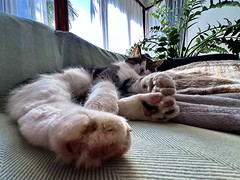

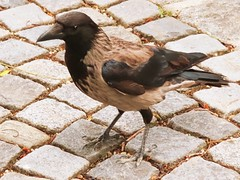

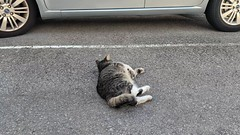

In [2]:
from IPython.display import display, Image

image_files = sorted(download_folder.glob("*.jpg"))

print(f"Saved images: {len(image_files)}")

for image_file in image_files[:3]:
    display(Image(filename=str(image_file), width=300))
